In [ ]:
import csv
import matplotlib.pyplot as plt

In [ ]:
path = "astana_apartments.csv"

How the database looks like:


In [46]:
apartments = []

with open(path, 'r', encoding='utf-8') as file:
    reader = csv.DictReader(file)
    for row in reader:
        row['price'] = int(row['price'])
        row['area'] = float(row['area'])
        apartments.append(row)

for apt in apartments[:5]:
    print(apt['price'], apt['area'], apt['rooms'], apt['address'], apt['year_built'])

print("Number of apartments in the database:", len(apartments))

135000000 115.0 3 Нура р-н, Толе би 2024
82500000 103.0 3 Нура р-н, Улы Дала 27 — Толе Би 2023
22000000 39.1 1 Алматы р-н, Мустафина 2007
76500000 87.0 3 Сарайшык р-н, Шамши Калдаяков 2025
25500000 55.3 2 Алматы р-н, Жумекен Нажимеденова 39 2023
Number of apartments in the database: 932


Number of Apartments by Rooms

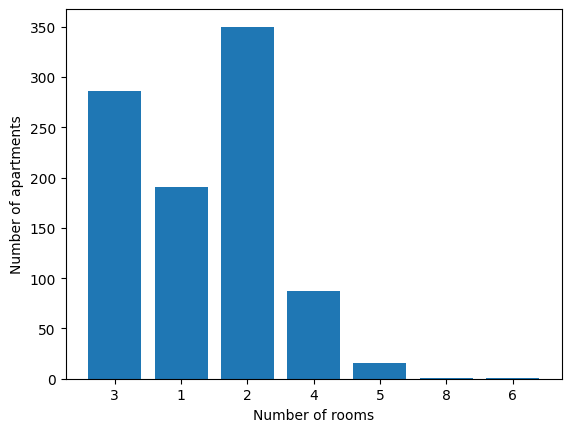

In [20]:
room_counts = {}

for apt in apartments:
    rooms = apt["rooms"]
    room_counts[rooms] = room_counts.get(rooms, 0) + 1

plt.bar(room_counts.keys(), room_counts.values())
plt.xlabel("Number of rooms")
plt.ylabel("Number of apartments")
plt.show()

Maximum and Minimum Prices, and Mean Value

In [31]:
prices = []

for apt in apartments:
    prices.append(apt["price"])

print("The most expensive price of apartment:", max(prices), "KZT")
print("The cheapest price of apartment:", min(prices), "KZT")
print("Mean value of prices:", round(sum(prices)/len(prices)), "KZT")

The most expensive price of apartment: 350000000 KZT
The cheapest price of apartment: 9309000 KZT
Mean value of prices: 51710422 KZT


Median Apartment Price

In [30]:
sorted_prices = sorted(prices)
middle = len(sorted_prices)//2

print("Median price:", (sorted_prices[middle-1] + sorted_prices[middle])/2, "KZT")

Median price: 40027400.0 KZT


Distribution of Apartment Prices: we divide per 10 million tenge(0-10, 10-20, ..., 150+)


In [74]:
prices_mln = []
for p in prices:
    prices_mln.append(p / 1000000)

edges = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150]

labels = []
counts = []

for i in range(len(edges) - 1):
    start = edges[i]
    end = edges[i + 1]
    count = 0
    for p in prices_mln:
        if p >= start and p < end:
            count = count + 1
    labels.append(str(start) + "–" + str(end))
    counts.append(count)


count = 0
for p in prices_mln:
    if p >= 150:
        count = count + 1
labels.append("150+")
counts.append(count)

for i in range(len(labels)):
    print(labels[i]+"mln KZT", counts[i], "apartments")
print("Total:", sum(counts))

0–10mln KZT 2 apartments
10–20mln KZT 38 apartments
20–30mln KZT 198 apartments
30–40mln KZT 217 apartments
40–50mln KZT 153 apartments
50–60mln KZT 99 apartments
60–70mln KZT 65 apartments
70–80mln KZT 32 apartments
80–90mln KZT 33 apartments
90–100mln KZT 20 apartments
100–150mln KZT 45 apartments
150+mln KZT 30 apartments
Total: 932


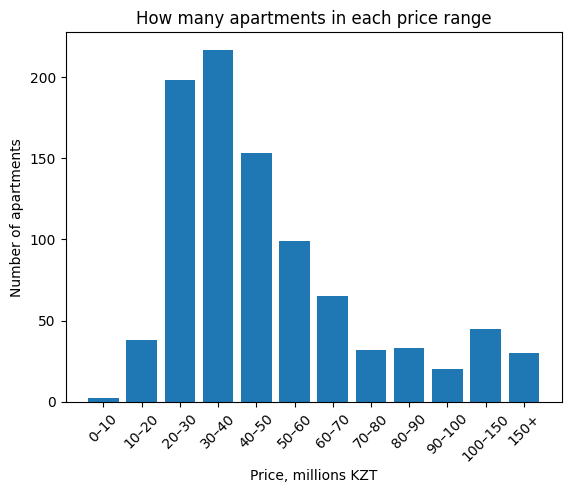

In [28]:
plt.bar(labels, counts)
plt.xlabel("Price, millions KZT")
plt.ylabel("Number of apartments")
plt.title("How many apartments in each price range")
plt.xticks(rotation=45)
plt.show()

Price per Square Metre = price/area

In [26]:
price_m2 = []

for apt in apartments:
    price_m2.append(apt["price"] / apt["area"])

print("Mean price per m2:", round(sum(price_m2)/len(price_m2)), "KZT")
print("Maximum price per m2:", round(max(price_m2)), "KZT")
print("Minimum price per m2:", round(min(price_m2)), "KZT")

Mean price per m2: 678396 KZT
Maximum price per m2: 1822917 KZT
Minimum price per m2: 254795 KZT


Average Apartment Price by Number of Rooms

In [25]:
for rooms in ["1", "2", "3", "4", "5"]:
    p = []

    for apt in apartments:
        if apt["rooms"] == rooms:
            p.append(apt["price"])

    print(rooms, "rooms:", round(sum(p)/len(p)), "KZT")

1 rooms: 25472217 KZT
2 rooms: 39327199 KZT
3 rooms: 60275775 KZT
4 rooms: 101332946 KZT
5 rooms: 176222630 KZT


Relationship between area and price

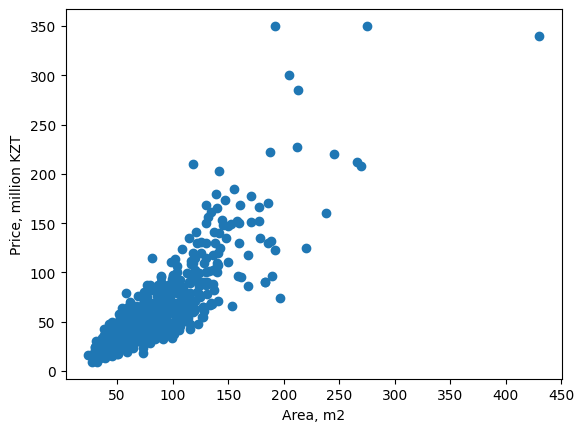

In [ ]:
areas = [apt["area"] for apt in apartments]

fig, ax = plt.subplots()
ax.scatter(areas, prices_mln)
ax.set_xlabel("Area, m2")
ax.set_ylabel("Price, million KZT")
plt.show()

Average Price per Square Metre by Number of Rooms

In [ ]:
for rooms in ["1", "2", "3", "4", "5"]:
    p = []

    for apt in apartments:
        if apt["rooms"] == rooms:
            p.append(apt["price"]/apt["area"])

    print(rooms, "rooms:", round(sum(p)/len(p)))

1 rooms: 640723
2 rooms: 682395
3 rooms: 661454
4 rooms: 754111
5 rooms: 887609


Average Price per Square Metre by District

In [41]:
districts = ["Нура р-н", "Есильский р-н", "Сарайшык р-н",
             "Алматы р-н", "Сарыарка р-н", "р-н Байконур"]
averages = []
for district in districts:
    p = []

    for apt in apartments:
        if district in apt["address"]:
            p.append(apt["price"]/apt["area"])
    avg = round(sum(p)/len(p))
    print(district, avg)
    averages.append(avg / 1000)

Нура р-н 710827
Есильский р-н 744338
Сарайшык р-н 635427
Алматы р-н 590262
Сарыарка р-н 540742
р-н Байконур 512711


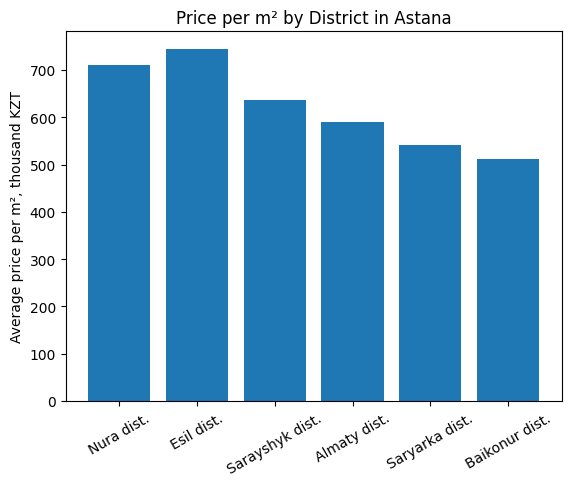

In [45]:
districts = ["Nura dist.", "Esil dist.", "Sarayshyk dist.",
             "Almaty dist.", "Saryarka dist.", "Baikonur dist."]

plt.bar(districts, averages)
plt.ylabel("Average price per m², thousand KZT")
plt.title("Price per m² by District in Astana")
plt.xticks(rotation=30)
plt.show()

Price based on the number of rooms

In [51]:
room1 = []
room2 = []
room3 = []
room4 = []

with open(path, 'r', encoding='utf-8') as file:
    reader = csv.DictReader(file, delimiter=",")
    for row in reader:
        rooms = row['rooms']
        price = int(row['price'])
        if rooms == "1":
            room1.append(price)
        elif rooms == "2":
            room2.append(price)
        elif rooms == "3":
            room3.append(price)
        elif rooms == "4":
            room4.append(price)

print("Number of one-room apartments:", len(room1), " Average price:", round(sum(room1) / len(room1)), "KZT")
print("Number of two-room apartments:", len(room2), " Average price:", round(sum(room2) / len(room2)), "KZT")
print("Number of three-room apartments:", len(room3), " Average price:", round(sum(room3) / len(room3)), "KZT")
print("Number of four-room apartments:", len(room4), " Average price:", round(sum(room4) / len(room4)), "KZT")

Number of one-room apartments: 191  Average price: 25472217 KZT
Number of two-room apartments: 350  Average price: 39327199 KZT
Number of three-room apartments: 286  Average price: 60275775 KZT
Number of four-room apartments: 87  Average price: 101332946 KZT


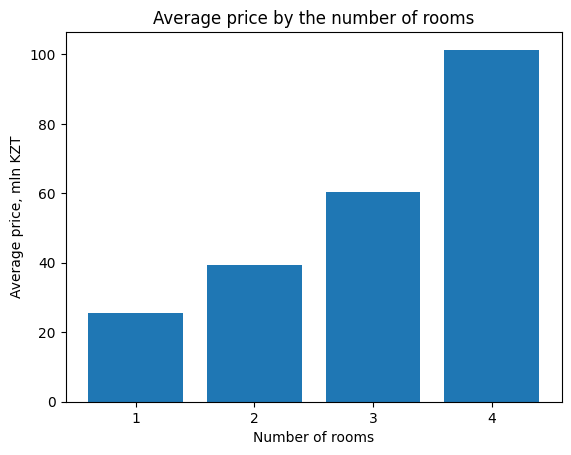

In [52]:
rooms_names = ["1", "2", "3", "4"]
averages = [sum(room1) / len(room1) / 1000000,
            sum(room2) / len(room2) / 1000000,
            sum(room3) / len(room3) / 1000000,
            sum(room4) / len(room4) / 1000000]

plt.bar(rooms_names, averages)
plt.xlabel("Number of rooms")
plt.ylabel("Average price, mln KZT")
plt.title("Average price by the number of rooms")
plt.show()

Building type

In [58]:
monolith = []
brick = []
panel = []

with open(path, 'r', encoding='utf-8') as file:
    reader = csv.DictReader(file, delimiter=",")
    for row in reader:
        house = row['building_type'].lower()
        m2 = int(row['price']) / float(row['area'])
        if "монолит" in house:
            monolith.append(m2)
        elif "кирпич" in house:
            brick.append(m2)
        elif "панел" in house:
            panel.append(m2)

print("Number of monolith buildings:", len(monolith), " Average price m²", round(sum(monolith) / len(monolith)))
print("Number of brick buildings: ", len(brick), " Average price m²", round(sum(brick) / len(brick)))
print("Number of panel buidings: ", len(panel), " Average price m²", round(sum(panel) / len(panel)))

Number of monolith buildings: 411  Average price m² 715414
Number of brick buildings:  276  Average price m² 636929
Number of panel buidings:  16  Average price m² 502262


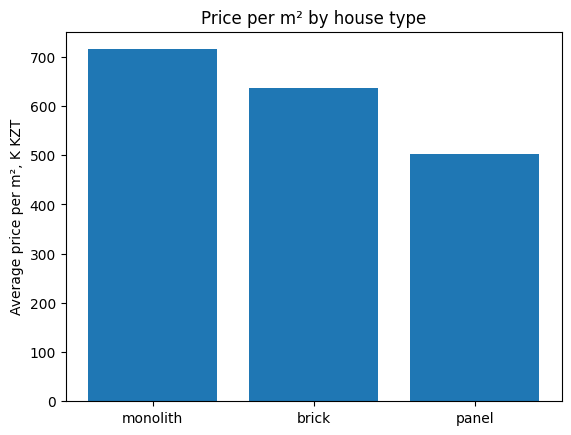

In [54]:
types = ["monolith", "brick", "panel"]
averages = [sum(monolith) / len(monolith) / 1000,
            sum(brick) / len(brick) / 1000,
            sum(panel) / len(panel) / 1000]

plt.bar(types, averages)
plt.ylabel("Average price per m², K KZT")
plt.title("Price per m² by house type")
plt.show()

Year of construction: old houses and new ones

In [61]:
old = []
y2000 = []
y2010 = []
new = []
building = []

for apt in apartments:
    year = int(apt['year_built'])
    m2 = apt['price'] / apt['area']

    if year < 2000:
        old.append(m2)
    elif year < 2010:
        y2000.append(m2)
    elif year < 2020:
        y2010.append(m2)
    elif year <= 2025:
        new.append(m2)
    else:
        building.append(m2)

print("before 2000", len(old), " Average price m²", round(sum(old) / len(old)))
print("2000–2009:", len(y2000), " Average price m²", round(sum(y2000) / len(y2000)))
print("2010–2019:", len(y2010), " Average price m²", round(sum(y2010) / len(y2010)))
print("2020–2025:", len(new), " Average price m²", round(sum(new) / len(new)))
print("being built:", len(building), " Average price m²", round(sum(building) / len(building)))

before 2000 23  Average price m² 457584
2000–2009: 51  Average price m² 552708
2010–2019: 181  Average price m² 622798
2020–2025: 351  Average price m² 722711
being built: 326  Average price m² 696793


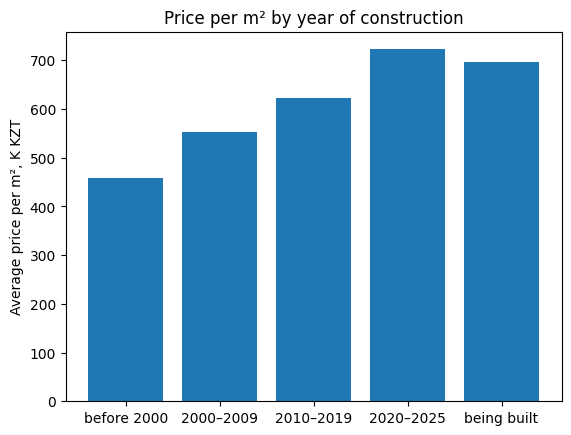

In [63]:
periods = ["before 2000", "2000–2009", "2010–2019", "2020–2025", "being built"]
averages = [sum(old) / len(old) / 1000,
            sum(y2000) / len(y2000) / 1000,
            sum(y2010) / len(y2010) / 1000,
            sum(new) / len(new) / 1000,
            sum(building) / len(building) / 1000]

plt.bar(periods, averages)
plt.ylabel("Average price per m², K KZT")
plt.title("Price per m² by year of construction")
plt.show()

Floor: first, last, or middle


In [66]:
first = []
last = []
middle_floor = []

with open(path, 'r', encoding='utf-8') as file:
    reader = csv.DictReader(file, delimiter=",")
    for row in reader:
        if row['floor'] == "" or row['total_floors'] == "":
            continue
        floor = int(row['floor'])
        total = int(row['total_floors'])
        m2 = int(row['price']) / float(row['area'])
        if floor == 1:
            first.append(m2)
        elif floor == total:
            last.append(m2)
        else:
            middle_floor.append(m2)

print("The first floor:", len(first), " Average price m²", round(sum(first) / len(first)))
print("The top floor:", len(last), " Average price m²", round(sum(last) / len(last)))
print("Middle floors:", len(middle_floor), " Average price m²", round(sum(middle_floor) / len(middle_floor)))

The first floor: 17  Average price m² 640714
The top floor: 73  Average price m² 668468
Middle floors: 712  Average price m² 695465


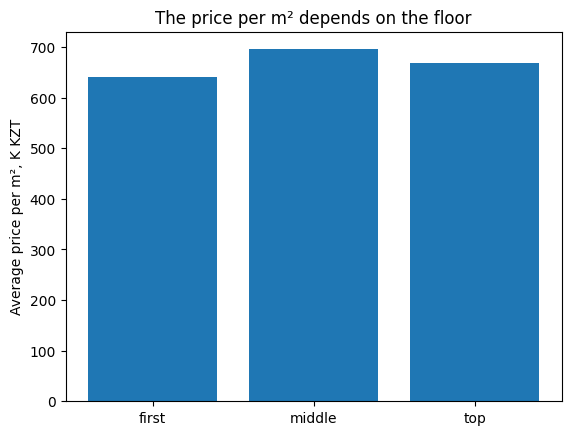

In [71]:
floors = ["first", "middle", "top"]
averages = [sum(first) / len(first) / 1000,
            sum(middle_floor) / len(middle_floor) / 1000,
            sum(last) / len(last) / 1000]

plt.bar(floors, averages)
plt.ylabel("Average price per m², K KZT")
plt.title("The price per m² depends on the floor")
plt.show()

The most expensive and the cheapest apartment per square meter

In [73]:
max_m2 = 0
min_m2 = 999999999
max_row = None
min_row = None

with open(path, 'r', encoding='utf-8') as file:
    reader = csv.DictReader(file, delimiter=",")
    for row in reader:
        m2 = int(row['price']) / float(row['area'])
        if m2 > max_m2:
            max_m2 = m2
            max_row = row
        if m2 < min_m2:
            min_m2 = m2
            min_row = row

print("The most expensive m²:", round(max_m2), "|", max_row['address'], "|", max_row['area'], "m² |", max_row['price'], "KZT")
print("The cheapest m²:", round(min_m2), "|", min_row['address'], "|", min_row['area'], "m² |", min_row['price'], "KZT")

The most expensive m²: 1822917 | Есильский р-н, Бухар жырау 26 — ВИДОВАЯ НА БОТАНИЧЕСКИЙ САД | 192 m² | 350000000 KZT
The cheapest m²: 254795 | Сарыарка р-н, Даулеткерей стр. 1а, стр. 3 | 73 m² | 18600000 KZT
